# 02 · Modélisation du risque de diabète

Objectif : **détecter les personnes diabétiques** à partir de 21 indicateurs de santé (CDC BRFSS 2015).

La classe positive ne représente que **15 %** des répondants : l'accuracy est trompeuse (un modèle qui prédit toujours « non diabétique » ferait 85 %). On suit donc la **ROC-AUC**, la **PR-AUC**, le **rappel** et le **F1** de la classe diabétique.

Toute la logique est dans `src/pipeline.py`, ce notebook la commente.

In [1]:
import sys, json
sys.path.append('../src')
import pandas as pd
from IPython.display import Image, display
import pipeline as P

X_tr, y_tr, X_te, y_te = P.load_splits('../data')
print('Train', X_tr.shape, '| Test', X_te.shape, '| prévalence', round(y_tr.mean(), 3))

Train (183579, 21) | Test (45895, 21) | prévalence 0.153


## 1. Comparaison de modèles

Trois modèles, évalués en validation croisée stratifiée 5 plis sur le train, puis sur le test :
- **Random Forest** : le modèle de départ (baseline)
- **Régression logistique** : modèle simple et interprétable
- **LightGBM** : gradient boosting, adapté aux données tabulaires

In [2]:
results, probas, thresholds, fitted = [], {}, {}, {}
for name, model in P.get_models().items():
    oof = P.oof_proba(model, X_tr, y_tr)
    thr = P.pick_thresholds(y_tr, oof)
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    g = P.global_metrics(y_te, p)
    results.append({'Modèle': name, 'ROC-AUC': g['roc_auc'], 'PR-AUC': g['pr_auc'],
                    'Rappel @0.5': P.metrics_at(y_te, p, 0.5)['rappel'],
                    'F1 @0.5': P.metrics_at(y_te, p, 0.5)['f1'],
                    'Seuil optimisé': thr['f1_max'],
                    'Rappel @seuil': P.metrics_at(y_te, p, thr['f1_max'])['rappel'],
                    'F1 @seuil': P.metrics_at(y_te, p, thr['f1_max'])['f1']})
    probas[name], thresholds[name], fitted[name] = p, thr, model
pd.DataFrame(results).round(3)

,Modèle,ROC-AUC,PR-AUC,Rappel @0.5,F1 @0.5,Seuil optimisé,Rappel @seuil,F1 @seuil
0,Random Forest (baseline),0.783,0.348,0.447,0.416,0.370,0.641,0.439
1,Régression logistique,0.811,0.412,0.760,0.449,0.577,0.669,0.462
2,LightGBM,0.820,0.446,0.173,0.269,0.227,0.642,0.475


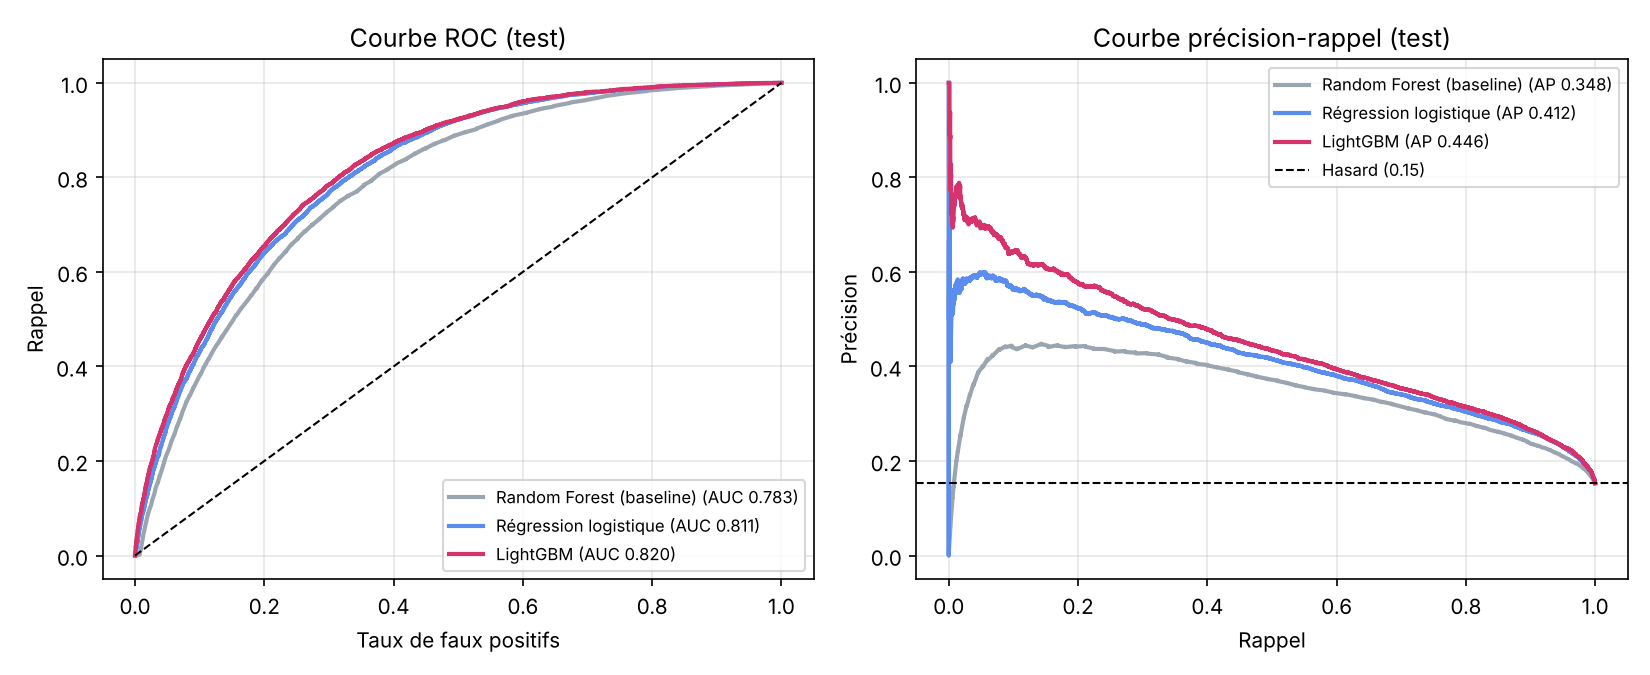

In [3]:
P.plot_roc_pr(y_te, probas, '../reports/figures/roc_pr_curves.png')
display(Image('../reports/figures/roc_pr_curves.png'))

**Lecture.** LightGBM a la meilleure capacité de classement (ROC-AUC 0,82, PR-AUC 0,45 contre 0,15 pour le hasard). Mais au seuil par défaut de 0,5, il ne détecte que ~17 % des diabétiques : **le problème principal n'est pas le modèle, c'est le seuil.**

## 2. Choix du seuil de décision

Le seuil est choisi sur les prédictions **out-of-fold du train** (jamais sur le test), selon deux objectifs :
- **F1 max** : meilleur équilibre précision / rappel
- **Dépistage** : détecter au moins 80 % des diabétiques, en acceptant plus de faux positifs (logique d'un dépistage, où rater un malade coûte plus cher qu'un test de confirmation)

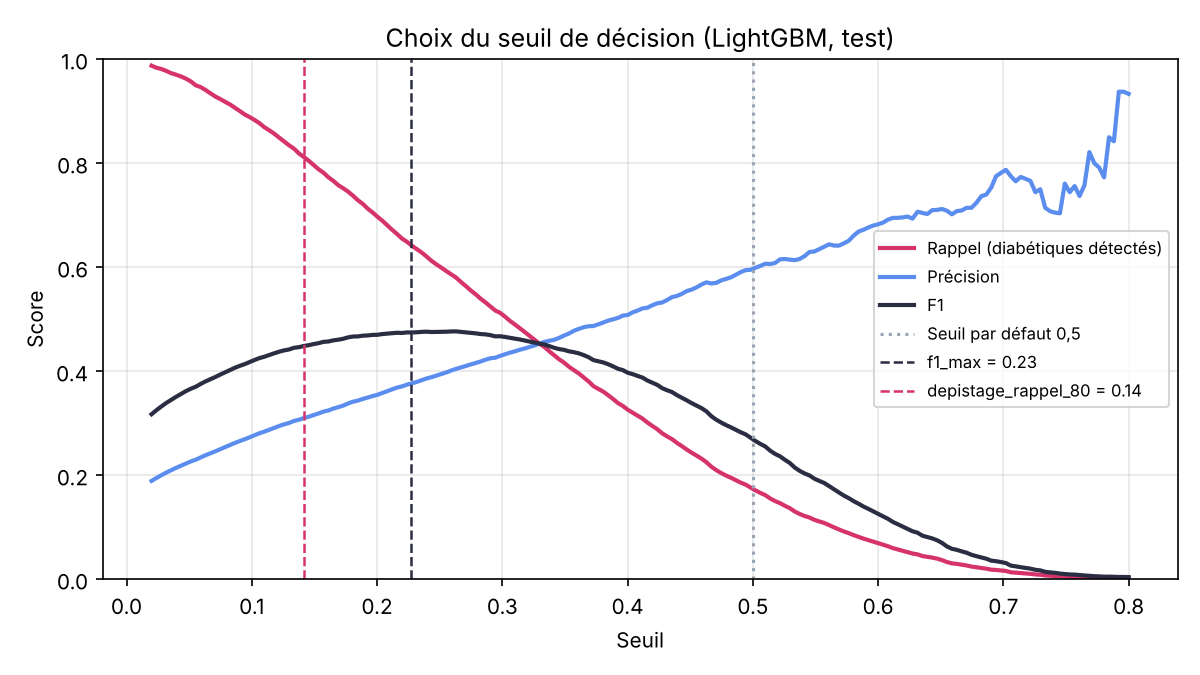

,"Seuil 0,5",F1 max,Dépistage (rappel ≥ 80 %)
seuil,0.500,0.227,0.142
precision,0.595,0.376,0.310
rappel,0.173,0.642,0.811
specificite,0.979,0.808,0.674
f1,0.269,0.475,0.449


In [4]:
best = 'LightGBM'
p, thr = probas[best], thresholds[best]
screen = [k for k in thr if k.startswith('depistage')][0]
P.plot_threshold_tradeoff(y_te, p, thr, '../reports/figures/threshold_tradeoff.png')
display(Image('../reports/figures/threshold_tradeoff.png'))
pd.DataFrame({'Seuil 0,5': P.metrics_at(y_te, p, 0.5),
              'F1 max': P.metrics_at(y_te, p, thr['f1_max']),
              'Dépistage (rappel ≥ 80 %)': P.metrics_at(y_te, p, thr[screen])}).drop('confusion').astype(float).round(3)

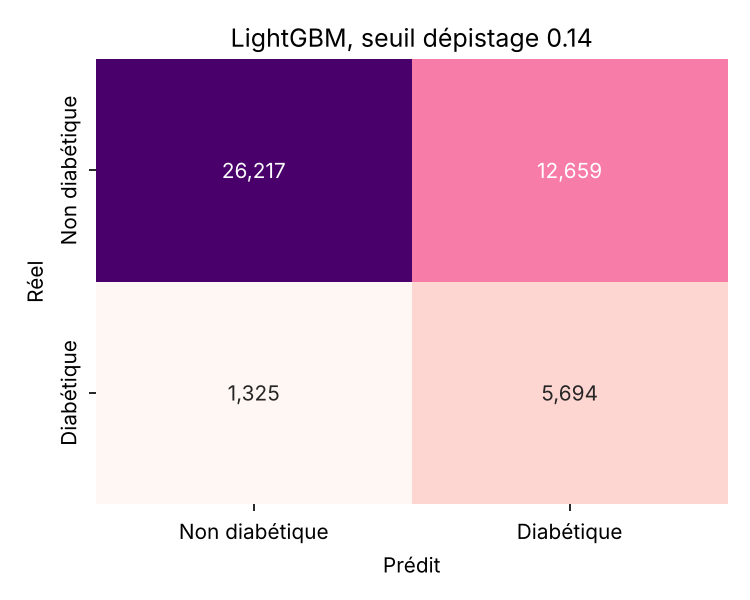

In [5]:
P.plot_confusion(y_te, p, thr[screen], f'LightGBM, seuil dépistage {thr[screen]:.2f}', '../reports/figures/confusion_depistage.png')
display(Image('../reports/figures/confusion_depistage.png'))

**Lecture.** Au seuil de dépistage, le modèle détecte **~81 % des diabétiques** (contre ~17 % à 0,5). En contrepartie, environ 1 alerte sur 3 est un vrai diabétique : acceptable pour orienter vers un test sanguin de confirmation, pas pour poser un diagnostic.

## 3. Interprétation (SHAP)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/usr/local/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


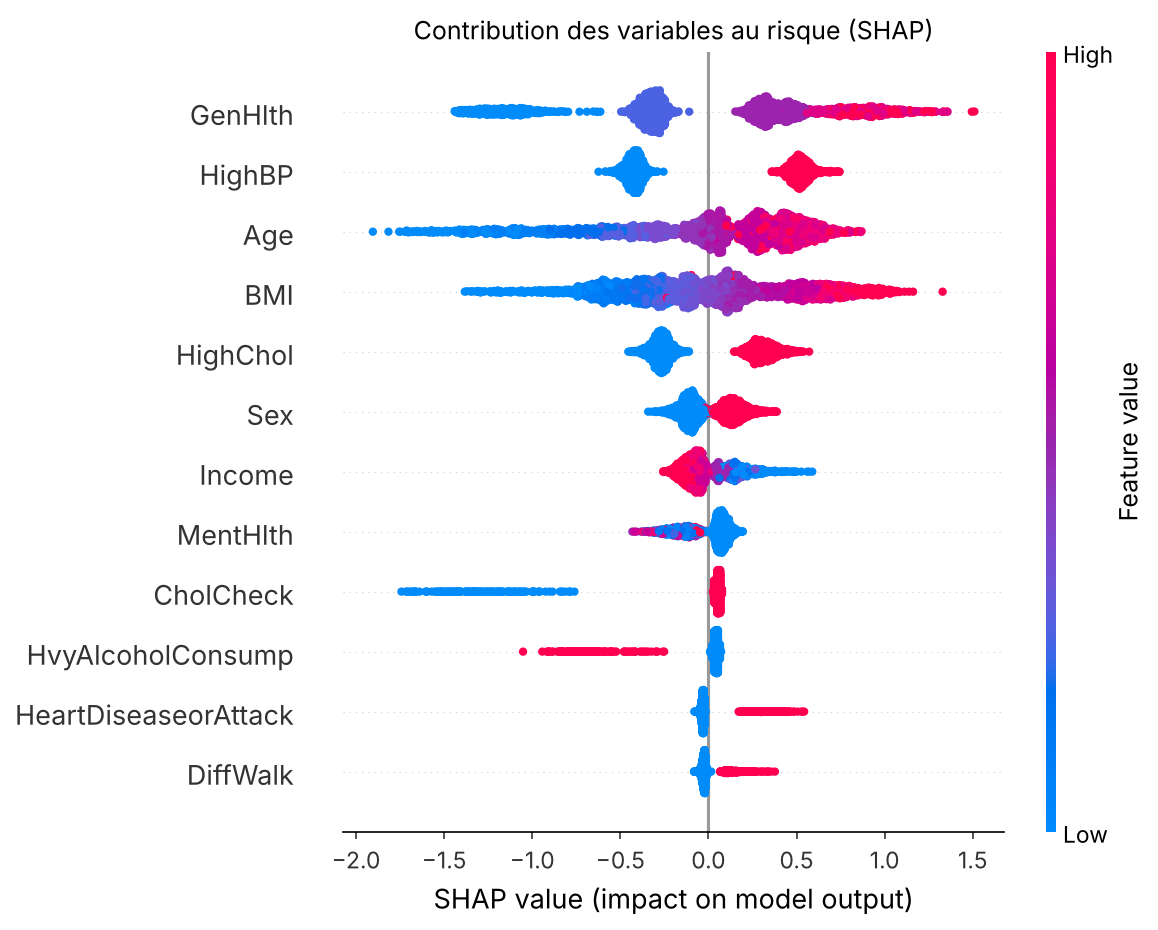

GenHlth              0.569
HighBP               0.469
Age                  0.425
BMI                  0.397
HighChol             0.290
Sex                  0.127
Income               0.115
MentHlth             0.107
CholCheck            0.106
HvyAlcoholConsump    0.077
dtype: float64

In [6]:
imp = P.plot_shap(fitted[best], X_te, '../reports/figures/shap_summary.png')
display(Image('../reports/figures/shap_summary.png'))
imp.head(10).round(3)

**Lecture.** Les facteurs qui poussent le plus le risque sont un **état de santé général perçu mauvais** (`GenHlth`), l'**hypertension**, l'**âge**, l'**IMC** et le **cholestérol**, cohérents avec la littérature médicale. Un **revenu** plus faible augmente aussi le risque prédit, ce qui reflète des inégalités sociales de santé (corrélation, pas causalité).

## 4. Limites
- Données **déclaratives** (enquête téléphonique) : biais de mémoire et de désirabilité.
- Variables surtout binaires ou ordinales : le plafond de performance est atteint vite (ROC-AUC ~0,82 dans la littérature sur ce jeu de données).
- Outil d'aide au dépistage et d'analyse, **pas un outil de diagnostic**.